# Retention Lite resume and decoding

Resume training from step 12,000 to 20,000

In [1]:
!pip install bert-score -q
import os, math, json, time, random, zipfile, csv, glob
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_GPUS = torch.cuda.device_count()
print(DEVICE, NUM_GPUS)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.2 MB/s eta 0:00:00
cuda 2


In [2]:
SEED = 42
random.seed(SEED); torch.manual_seed(SEED)

                                                                                     
cands = [p for p in glob.glob("/kaggle/input/**/checkpoint.pt", recursive=True) if "retention_lite" in p]
assert cands, "checkpoint.pt not found under /kaggle/input - add your dataset as an input"
SRC_DIR = os.path.dirname(cands[0])
print("Using source dir:", SRC_DIR)
SRC_CKPT      = os.path.join(SRC_DIR, "checkpoint.pt")
TOKENIZER_SRC = os.path.join(SRC_DIR, "bpe_tokenizer.json")
CORPUS_SRC    = os.path.join(SRC_DIR, "tokenized_corpus.pt")
for p in (SRC_CKPT, TOKENIZER_SRC, CORPUS_SRC): assert os.path.exists(p), p

                                                                                           
ARCH_NAME = "retention_lite"
D_MODEL, N_LAYERS, N_HEADS, D_FF = 640, 12, 10, 1792
BLOCK_SIZE, CHUNK_SIZE, ROPE_BASE, MAX_POSITIONS = 1024, 128, 10000.0, 4096
MICRO_BATCH_SIZE, GRAD_ACCUM_STEPS = 8, 2                                             
DROPOUT = 0.0                                                                                                                   

                                                   
TARGET_STEP = 20000
RESUME_WARMUP = 100                                                   
PEAK_LR, MIN_LR = 2e-4, 1e-5
WEIGHT_DECAY = 0.1
                                                                                                       
                                                                                                           
TIME_BUDGET_HOURS = 2.3
TIME_BUDGET_SECONDS = TIME_BUDGET_HOURS * 3600
EVAL_EVERY, CHECKPOINT_EVERY = 500, 500

TARGET_WORDS, MAX_GEN_TOKENS = 128, 400

OUTPUT_DIR = "/kaggle/working/cs781_phase1/retention_lite_resume20k"
os.makedirs(OUTPUT_DIR, exist_ok=True)
WORK_CKPT   = os.path.join(OUTPUT_DIR, "checkpoint.pt")
MODEL_PATH  = os.path.join(OUTPUT_DIR, "model.pt")
LOSS_PLOT   = os.path.join(OUTPUT_DIR, "loss.png")
PRED_PATH   = os.path.join(OUTPUT_DIR, "prediction.json")
SUB_ZIP     = os.path.join(OUTPUT_DIR, "submission.zip")
LOG_PATH    = "/kaggle/working/cs781_phase1/experiment_log.csv"

Using source dir: /kaggle/input/datasets/akshatkasarwal/lightweight-dataset/cs781_phase1/retention_lite_train_supreme_court-train_acts-train_high_courts-train_tribunals


In [3]:
class ByteLevelBPETokenizer:
    SPECIAL_TOKENS = ["<pad>", "<unk>", "<s>", "</s>"]

    def __init__(self):
        self.merges = {}
        self.id_to_bytes = {i: bytes([i]) for i in range(256)}
        self.special_to_id = {}
        for i, tok in enumerate(self.SPECIAL_TOKENS):
            tid = 256 + i
            self.special_to_id[tok] = tid
            self.id_to_bytes[tid] = tok.encode("utf-8")

    @property
    def vocab_size(self):
        return len(self.id_to_bytes)

    @staticmethod
    def _pair_counts(sequences):
        counts = {}
        for seq, freq in sequences:
            for pair in zip(seq, seq[1:]):
                counts[pair] = counts.get(pair, 0) + freq
        return counts

    @staticmethod
    def _apply_merge(seq, pair, new_id):
        out, i = [], 0
        while i < len(seq):
            if i < len(seq) - 1 and (seq[i], seq[i + 1]) == pair:
                out.append(new_id); i += 2
            else:
                out.append(seq[i]); i += 1
        return out

    def train(self, text, vocab_size, max_words=100000, verbose=True):
        num_merges = vocab_size - self.vocab_size
        if num_merges <= 0:
            return self

        word_freq = {}
        for word in text.split():
            word_freq[word] = word_freq.get(word, 0) + 1
        if len(word_freq) > max_words:
            word_freq = dict(sorted(word_freq.items(), key=lambda kv: -kv[1])[:max_words])
        sequences = [[list(word.encode("utf-8")), freq] for word, freq in word_freq.items()]

        next_id = self.vocab_size
        for step in range(num_merges):
            counts = self._pair_counts(sequences)
            if not counts:
                break
            best_pair = max(counts, key=counts.get)
            self.merges[best_pair] = next_id
            self.id_to_bytes[next_id] = self.id_to_bytes[best_pair[0]] + self.id_to_bytes[best_pair[1]]
            for entry in sequences:
                entry[0] = self._apply_merge(entry[0], best_pair, next_id)
            if verbose and (step + 1) % 1000 == 0:
                print(step + 1, next_id + 1)
            next_id += 1
        return self

    def _encode_word(self, word):
        seq = list(word.encode("utf-8"))
        while len(seq) > 1:
            mergeable = [p for p in zip(seq, seq[1:]) if p in self.merges]
            if not mergeable:
                break
            pair = min(mergeable, key=lambda p: self.merges[p])
            seq = self._apply_merge(seq, pair, self.merges[pair])
        seq.append(self.special_to_id["</s>"])
        return seq

    def encode(self, text):
        cache = self.__dict__.setdefault("_word_cache", {})
        ids = []
        for word in text.split():
            w = cache.get(word)
            if w is None:
                w = self._encode_word(word)
                if len(cache) < 3000000:
                    cache[word] = w
            ids.extend(w)
        return ids

    def encode_to_array(self, text, max_tokens, slice_chars=20000000):
        """Same output as the naive version, but (1) caches word -> ids and (2) processes the text in slices
        so we never materialise a list of ~100M word strings."""
        cache = self.__dict__.setdefault("_word_cache", {})
        arr = np.empty(max_tokens, dtype=np.int32)
        n, pos, L = 0, 0, len(text)
        while pos < L and n < max_tokens:
            end = min(pos + slice_chars, L)
            while end < L and not text[end].isspace():
                end += 1
            buf = []
            for word in text[pos:end].split():
                w = cache.get(word)
                if w is None:
                    w = self._encode_word(word)
                    if len(cache) < 3000000:
                        cache[word] = w
                buf.extend(w)
                if n + len(buf) >= max_tokens:
                    break
            m = min(len(buf), max_tokens - n)
            arr[n:n + m] = buf[:m]
            n += m
            pos = end
            print(f"  tokenized {n:,} / {max_tokens:,}")
        return arr[:n]

    def decode(self, ids):
        words, current = [], []
        for i in ids:
            if i == self.special_to_id["</s>"]:
                if current:
                    words.append(b"".join(self.id_to_bytes.get(int(t), b"") for t in current).decode("utf-8", errors="ignore"))
                    current = []
            else:
                current.append(i)
        if current:
            words.append(b"".join(self.id_to_bytes.get(int(t), b"") for t in current).decode("utf-8", errors="ignore"))
        return " ".join(words)

    def save(self, path):
        merges_serializable = {f"{a},{b}": nid for (a, b), nid in self.merges.items()}
        with open(path, "w", encoding="utf-8") as f:
            json.dump({"merges": merges_serializable}, f)

    @classmethod
    def load(cls, path):
        tok = cls()
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        for pair_str, nid in data["merges"].items():
            a, b = (int(x) for x in pair_str.split(","))
            tok.merges[(a, b)] = nid
            tok.id_to_bytes[nid] = tok.id_to_bytes[a] + tok.id_to_bytes[b]
        return tok

In [4]:
class RMSNorm(nn.Module):
    """RMS normalization without mean subtraction."""
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
        self.eps = eps

    def forward(self, x):
        rms = x.pow(2).mean(dim=-1, keepdim=True)
        return self.weight * x * torch.rsqrt(rms + self.eps)


def rotate_half(x):
    x1, x2 = x.chunk(2, dim=-1)                                                                    
    return torch.cat((-x2, x1), dim=-1)


class RotaryEmbedding(nn.Module):
    def __init__(self, dim, max_seq_len, base=10000.0):
        super().__init__()
        inv_freq = 1.0 / (base ** (torch.arange(0, dim, 2, dtype=torch.float32) / dim))
        freqs = torch.outer(torch.arange(max_seq_len, dtype=torch.float32), inv_freq)
        emb = torch.cat((freqs, freqs), dim=-1)
        self.register_buffer("cos", emb.cos()[None, None, :, :], persistent=False)
        self.register_buffer("sin", emb.sin()[None, None, :, :], persistent=False)

    def forward(self, x, offset=0):
        T = x.size(-2)
        cos = self.cos[:, :, offset:offset + T, :].to(x.dtype)
        sin = self.sin[:, :, offset:offset + T, :].to(x.dtype)
        return x * cos + rotate_half(x) * sin


class GeGLU(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.gate = nn.Linear(d_model, d_ff, bias=False)
        self.up = nn.Linear(d_model, d_ff, bias=False)
        self.down = nn.Linear(d_ff, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(self.down(F.gelu(self.gate(x)) * self.up(x)))


def retention_chunkwise(q, k, v, log_gamma, state=None, chunk_size=128):
    """
    Chunkwise retention (RetNet). Equivalent to the recurrence
        S_t = gamma * S_{t-1} + k_t^T v_t ,   o_t = q_t S_t
    q, k: (B,H,T,dk)   v: (B,H,T,dv)   log_gamma: (H,) (negative)   state: (B,H,dk,dv) or None
    Inside a chunk: parallel (masked, decayed q k^T) v.  Across chunks: carry the (dk x dv) state.
    Memory/compute is linear in T; decoding (T=1) is O(1) per token. No softmax.
    """
    B, H, T, dk = q.shape
    dv = v.size(-1)
    if state is None:
        state = q.new_zeros(B, H, dk, dv)
    lg = log_gamma.view(1, H, 1, 1)
    outs = []
    for s in range(0, T, chunk_size):
        qc, kc, vc = q[:, :, s:s + chunk_size], k[:, :, s:s + chunk_size], v[:, :, s:s + chunk_size]
        L = qc.size(2)
        idx = torch.arange(L, device=q.device, dtype=q.dtype)
        diff = idx[:, None] - idx[None, :]                                          
        D = torch.exp(diff.clamp(min=0)[None, None] * lg) * (diff >= 0)                                   
        inner = ((qc @ kc.transpose(-1, -2)) * D) @ vc                                     
        q_decay = torch.exp((idx + 1).view(1, 1, L, 1) * lg)                              
        cross = (qc * q_decay) @ state                                                                        
        outs.append(inner + cross)
        k_decay = torch.exp((L - 1 - idx).view(1, 1, L, 1) * lg)                            
        state = torch.exp(L * lg) * state + (kc * k_decay).transpose(-1, -2) @ vc
    return torch.cat(outs, dim=2), state


class MultiScaleRetention(nn.Module):
    """RetNet-style multi-scale retention: per-head decay (fast ... slow), RoPE on q/k, per-head norm, swish output gate."""
    def __init__(self, d_model, n_heads, rope, chunk_size, dropout):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads, self.d_head, self.chunk_size = n_heads, d_model // n_heads, chunk_size
        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.g_proj = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.head_norm_w = nn.Parameter(torch.ones(n_heads, 1, self.d_head))
        self.rope = rope
        self.dropout = nn.Dropout(dropout)
                                                                                                 
        gamma = 1.0 - 2.0 ** (-5.0 - torch.arange(n_heads, dtype=torch.float32))
        self.register_buffer("log_gamma", torch.log(gamma), persistent=False)

    def _split(self, x):
        B, T, _ = x.shape
        return x.view(B, T, self.n_heads, self.d_head).transpose(1, 2)

    def forward(self, x, state=None, offset=0):
        B, T, C = x.shape
        q = self._split(self.q_proj(x)) * (self.d_head ** -0.5)
        k = self._split(self.k_proj(x))
        v = self._split(self.v_proj(x))
        q, k = self.rope(q, offset), self.rope(k, offset)
        with torch.autocast(device_type=x.device.type, enabled=False):                                    
            o, new_state = retention_chunkwise(q.float(), k.float(), v.float(), self.log_gamma, state, self.chunk_size)
            o = o * torch.rsqrt(o.pow(2).mean(dim=-1, keepdim=True) + 1e-6) * self.head_norm_w                      
        o = o.to(x.dtype).transpose(1, 2).contiguous().view(B, T, C)
        o = o * F.silu(self.g_proj(x))
        return self.dropout(self.out_proj(o)), new_state


class RetentionBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, rope, chunk_size, dropout):
        super().__init__()
        self.norm_ret = RMSNorm(d_model)
        self.retention = MultiScaleRetention(d_model, n_heads, rope, chunk_size, dropout)
        self.norm_ffn = RMSNorm(d_model)
        self.ffn = GeGLU(d_model, d_ff, dropout)

    def forward(self, x, state=None, offset=0):
        h, new_state = self.retention(self.norm_ret(x), state=state, offset=offset)
        x = x + h
        return x + self.ffn(self.norm_ffn(x)), new_state


class RetentionLM(nn.Module):
    """
    Efficient / lightweight Transformer: softmax attention replaced by multi-scale retention.
    Training: chunkwise-parallel, O(T) memory. Inference: constant-size recurrent state (no KV cache growth).
    """
    def __init__(self, vocab_size, d_model, n_layers, n_heads, d_ff, max_pos,
                 chunk_size=128, dropout=0.1, rope_base=10000.0, tie_weights=True):
        super().__init__()
        self.max_pos = max_pos
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.emb_dropout = nn.Dropout(dropout)
        self.rope = RotaryEmbedding(d_model // n_heads, max_pos, rope_base)
        self.blocks = nn.ModuleList([RetentionBlock(d_model, n_heads, d_ff, self.rope, chunk_size, dropout) for _ in range(n_layers)])
        self.final_norm = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        if tie_weights:
            self.lm_head.weight = self.token_emb.weight
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def _run(self, idx, states=None, offset=0):
        if offset + idx.size(1) > self.max_pos:
            raise ValueError(f"Position {offset + idx.size(1)} exceeds RoPE table size {self.max_pos}")
        x = self.emb_dropout(self.token_emb(idx))
        new_states = []
        for i, blk in enumerate(self.blocks):
            x, s = blk(x, state=None if states is None else states[i], offset=offset)
            new_states.append(s)
        return self.lm_head(self.final_norm(x)), new_states

    def forward(self, idx, targets=None):
        logits, _ = self._run(idx)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_p=0.95, eos_id=None, stop_after_eos=None):
        """Prefill prompt (chunkwise) -> recurrent decoding. Returns ONLY the new tokens."""
        self.eval()
        logits, states = self._run(idx)
        P, out, n_eos = idx.size(1), [], 0
        for t in range(max_new_tokens):
            probs = torch.softmax(logits[:, -1, :] / max(temperature, 1e-5), dim=-1)
            sorted_probs, sorted_idx = torch.sort(probs, descending=True, dim=-1)
            cumulative = torch.cumsum(sorted_probs, dim=-1)
            remove = cumulative > top_p
            remove[:, 1:] = remove[:, :-1].clone()
            remove[:, 0] = False
            sorted_probs = sorted_probs.masked_fill(remove, 0.0)
            sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
            nxt = torch.gather(sorted_idx, -1, torch.multinomial(sorted_probs, 1))
            out.append(nxt)
            if stop_after_eos is not None and eos_id is not None and idx.size(0) == 1:
                n_eos += int(nxt.item() == eos_id)
                if n_eos >= stop_after_eos:
                    break
            if t < max_new_tokens - 1:
                logits, states = self._run(nxt, states=states, offset=P + t)
        return torch.cat(out, dim=1)

In [5]:
                                                                     
tokenizer = ByteLevelBPETokenizer.load(TOKENIZER_SRC)
VOCAB_SIZE = tokenizer.vocab_size
EOS_ID = tokenizer.special_to_id["</s>"]
print("vocab", VOCAB_SIZE)

cache = torch.load(CORPUS_SRC, weights_only=False)
train_ids, val_ids = torch.from_numpy(cache["train_ids"]), torch.from_numpy(cache["val_ids"])
del cache
print(len(train_ids), len(val_ids))

def make_blocks(ids, block_size):
    n = (len(ids) // block_size) * block_size
    return torch.from_numpy(np.asarray(ids[:n], dtype=np.int64)).view(-1, block_size)

train_blocks, val_blocks = make_blocks(train_ids, BLOCK_SIZE), make_blocks(val_ids, BLOCK_SIZE)

class BlockDataset(Dataset):
    def __init__(self, blocks): self.blocks = blocks
    def __len__(self): return len(self.blocks)
    def __getitem__(self, i):
        x = self.blocks[i]; return x[:-1], x[1:]

train_loader = DataLoader(BlockDataset(train_blocks), batch_size=MICRO_BATCH_SIZE, shuffle=True, drop_last=True)
val_loader   = DataLoader(BlockDataset(val_blocks),   batch_size=MICRO_BATCH_SIZE, shuffle=False, drop_last=True)

                                                      
raw_model = RetentionLM(vocab_size=VOCAB_SIZE, d_model=D_MODEL, n_layers=N_LAYERS, n_heads=N_HEADS, d_ff=D_FF,
                        max_pos=MAX_POSITIONS, chunk_size=CHUNK_SIZE, dropout=DROPOUT, rope_base=ROPE_BASE,
                        tie_weights=True).to(DEVICE)
n_params = sum(p.numel() for p in raw_model.parameters())
print(f"Parameters: {n_params/1e6:.2f}M")
model = nn.DataParallel(raw_model) if NUM_GPUS > 1 else raw_model

optimizer = torch.optim.AdamW(raw_model.parameters(), lr=PEAK_LR, weight_decay=WEIGHT_DECAY, betas=(0.9, 0.95))
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

load_path = WORK_CKPT if os.path.exists(WORK_CKPT) else SRC_CKPT                                                              
print("Loading", load_path)
ck = torch.load(load_path, map_location="cpu", weights_only=False)
assert str(ck["run_config"]["D_MODEL"]) == str(D_MODEL) and str(ck["run_config"]["N_LAYERS"]) == str(N_LAYERS)
assert str(ck["run_config"]["VOCAB_SIZE"]) == str(VOCAB_SIZE)
raw_model.load_state_dict(ck["model_state"])
optimizer.load_state_dict(ck["optimizer_state"])
scaler.load_state_dict(ck["scaler_state"])
step = ck["step"]
START_STEP = ck.get("start_step", step)                                                                                   
prev_elapsed = ck.get("elapsed_resume", 0.0)
train_loss_history, val_loss_history, step_history = ck["train_loss_history"], ck["val_loss_history"], ck["step_history"]
del ck
print(f"Resumed at step {step} (resume started at {START_STEP}), target {TARGET_STEP}")

def evaluate(loader, max_batches=50):
    model.eval(); losses = []
    with torch.no_grad():
        for i, (x, y) in enumerate(loader):
            if i >= max_batches: break
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
                _, loss = model(x, y); loss = loss.mean()
            losses.append(loss.item())
    model.train()
    return sum(losses) / max(1, len(losses))

base_loss = evaluate(val_loader, max_batches=200)
print(f"BASELINE val loss @step {step}: {base_loss:.4f}  ppl {math.exp(base_loss):.3f}   (old run ended at 1.6234 / 5.070)")

vocab 12000
200000000 5000000
Parameters: 73.57M
Loading /kaggle/input/datasets/akshatkasarwal/lightweight-dataset/cs781_phase1/retention_lite_train_supreme_court-train_acts-train_high_courts-train_tribunals/checkpoint.pt
Resumed at step 12000 (resume started at 12000), target 20000


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


BASELINE val loss @step 12000: 1.6234  ppl 5.070   (old run ended at 1.6234 / 5.070)


In [6]:
                                                        
def lr_at(step, elapsed):
    p_step = (step - START_STEP) / max(1, TARGET_STEP - START_STEP)
    p_time = elapsed / TIME_BUDGET_SECONDS
    p = min(1.0, max(p_step, p_time))
    warm = min(1.0, (step - START_STEP + 1) / RESUME_WARMUP)
    return (MIN_LR + 0.5 * (PEAK_LR - MIN_LR) * (1 + math.cos(math.pi * p))) * warm

def save_ckpt(path, elapsed):
    tmp = path + ".tmp"
    torch.save({"step": step, "start_step": START_STEP, "elapsed_resume": elapsed,
                "model_state": raw_model.state_dict(), "optimizer_state": optimizer.state_dict(),
                "scaler_state": scaler.state_dict(), "train_loss_history": train_loss_history,
                "val_loss_history": val_loss_history, "step_history": step_history,
                "run_config": {"D_MODEL": D_MODEL, "N_LAYERS": N_LAYERS, "N_HEADS": N_HEADS, "D_FF": D_FF,
                               "BLOCK_SIZE": BLOCK_SIZE, "VOCAB_SIZE": VOCAB_SIZE, "CHUNK_SIZE": CHUNK_SIZE,
                               "ROPE_BASE": ROPE_BASE, "ARCH_NAME": ARCH_NAME}}, tmp)
    os.replace(tmp, path)

t0 = time.time()
model.train()
def infinite_batches(loader):
    while True:
        yield from loader

data_iter = infinite_batches(train_loader)
while step < TARGET_STEP:
    elapsed_now = prev_elapsed + (time.time() - t0)
    if elapsed_now >= TIME_BUDGET_SECONDS:
        print("Time budget reached - stopping."); break
    optimizer.zero_grad(set_to_none=True)
    accum_loss = 0.0
    for _ in range(GRAD_ACCUM_STEPS):
        x, y = next(data_iter)
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
            _, loss = model(x, y); loss = loss.mean() / GRAD_ACCUM_STEPS
        scaler.scale(loss).backward()
        accum_loss += loss.item()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(raw_model.parameters(), 1.0)
    lr_now = lr_at(step, elapsed_now)
    for g in optimizer.param_groups: g["lr"] = lr_now
    scaler.step(optimizer); scaler.update()
    step += 1
    if step % 50 == 0:
        train_loss_history.append(accum_loss); step_history.append(step)
        print(step, round(accum_loss, 4), f"{lr_now:.2e}", f"{elapsed_now/3600:.2f}h")
    if step % EVAL_EVERY == 0:
        v = evaluate(val_loader); val_loss_history.append((step, v))
        print("eval", step, round(v, 4), "ppl", round(math.exp(v), 3))
    if step % CHECKPOINT_EVERY == 0:
        save_ckpt(WORK_CKPT, prev_elapsed + (time.time() - t0))

training_time = prev_elapsed + (time.time() - t0)
save_ckpt(WORK_CKPT, training_time)
final_val_loss = evaluate(val_loader, max_batches=200)
final_val_ppl = math.exp(final_val_loss)
print(f"DONE step {step}. val loss {base_loss:.4f} -> {final_val_loss:.4f} | ppl {math.exp(base_loss):.3f} -> {final_val_ppl:.3f} | {training_time/3600:.2f} h")

12050 1.4392 1.00e-04 0.01h
12100 1.4265 2.00e-04 0.02h
12150 1.6257 2.00e-04 0.04h
12200 1.7703 2.00e-04 0.05h
12250 1.4631 2.00e-04 0.06h
12300 1.6256 1.99e-04 0.07h
12350 1.6892 1.99e-04 0.08h
12400 1.4322 1.99e-04 0.10h
12450 1.309 1.99e-04 0.11h
12500 1.6259 1.98e-04 0.12h
eval 12500 1.6789 ppl 5.36
12550 1.4915 1.98e-04 0.14h
12600 1.7729 1.97e-04 0.15h
12650 1.6261 1.97e-04 0.16h
12700 1.4997 1.96e-04 0.17h
12750 1.538 1.96e-04 0.18h
12800 1.6508 1.95e-04 0.20h
12850 1.6283 1.95e-04 0.21h
12900 1.5912 1.94e-04 0.22h
12950 1.4022 1.93e-04 0.23h
13000 1.6676 1.93e-04 0.24h
eval 13000 1.6709 ppl 5.317
13050 1.6526 1.92e-04 0.26h
13100 1.5453 1.91e-04 0.27h
13150 1.8285 1.90e-04 0.28h
13200 1.6052 1.90e-04 0.30h
13250 1.573 1.89e-04 0.31h
13300 1.6334 1.88e-04 0.32h
13350 1.5254 1.87e-04 0.33h
13400 1.4156 1.86e-04 0.34h
13450 1.5851 1.85e-04 0.36h
13500 1.4847 1.84e-04 0.37h
eval 13500 1.6471 ppl 5.192
13550 1.3389 1.83e-04 0.38h
13600 1.7335 1.82e-04 0.39h
13650 1.3198 1.81e-04 0.

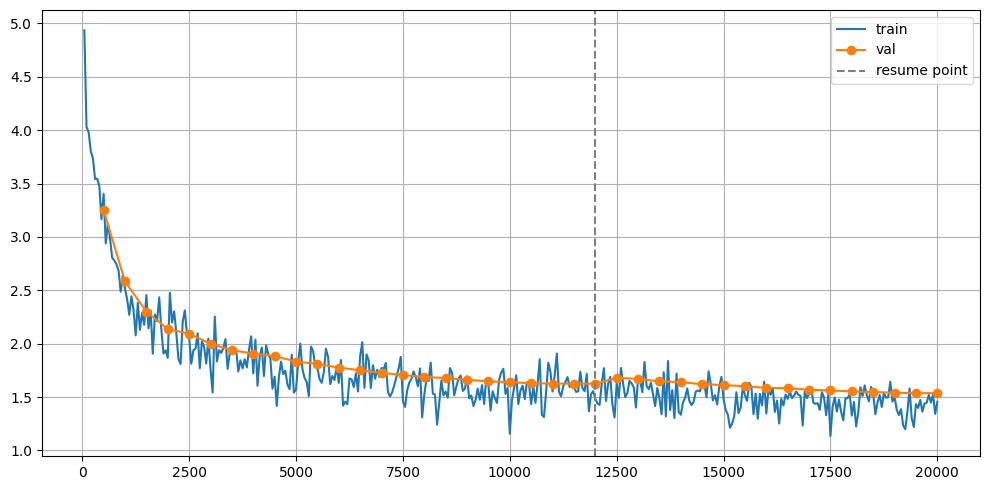

RetentionLM(
  (token_emb): Embedding(12000, 640)
  (emb_dropout): Dropout(p=0.0, inplace=False)
  (rope): RotaryEmbedding()
  (blocks): ModuleList(
    (0-11): 12 x RetentionBlock(
      (norm_ret): RMSNorm()
      (retention): MultiScaleRetention(
        (q_proj): Linear(in_features=640, out_features=640, bias=False)
        (k_proj): Linear(in_features=640, out_features=640, bias=False)
        (v_proj): Linear(in_features=640, out_features=640, bias=False)
        (g_proj): Linear(in_features=640, out_features=640, bias=False)
        (out_proj): Linear(in_features=640, out_features=640, bias=False)
        (rope): RotaryEmbedding()
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (norm_ffn): RMSNorm()
      (ffn): GeGLU(
        (gate): Linear(in_features=640, out_features=1792, bias=False)
        (up): Linear(in_features=640, out_features=1792, bias=False)
        (down): Linear(in_features=1792, out_features=640, bias=False)
        (dropout): Dropout(p=0.0, inpl

In [7]:
                                                                      
torch.save({"state_dict": raw_model.state_dict(),
            "config": {"vocab_size": VOCAB_SIZE, "d_model": D_MODEL, "n_layers": N_LAYERS, "n_heads": N_HEADS, "d_ff": D_FF,
                       "max_pos": MAX_POSITIONS, "train_context": BLOCK_SIZE, "chunk_size": CHUNK_SIZE,
                       "dropout": DROPOUT, "rope_base": ROPE_BASE, "arch_name": ARCH_NAME, "steps": step}}, MODEL_PATH)

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(step_history, train_loss_history, label="train")
if val_loss_history:
    vs, vl = zip(*val_loss_history); plt.plot(vs, vl, label="val", marker="o")
plt.axvline(START_STEP, color="gray", ls="--", label="resume point")
plt.legend(); plt.grid(True); plt.tight_layout(); plt.savefig(LOSS_PLOT, dpi=200); plt.show()

row = {"run_id": "retention_lite_resume20k", "arch": ARCH_NAME, "params_M": round(n_params/1e6, 2), "steps": step,
       "start_val_loss": round(base_loss, 6), "final_val_loss": round(final_val_loss, 6), "final_val_ppl": round(final_val_ppl, 4),
       "resume_hours": round(training_time/3600, 3), "peak_lr": PEAK_LR, "dropout": DROPOUT}
os.makedirs(os.path.dirname(LOG_PATH), exist_ok=True)
new = not os.path.exists(LOG_PATH)
with open(LOG_PATH, "a", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(row.keys()))
    if new: w.writeheader()
    w.writerow(row)

del optimizer, scaler, model                                            
torch.cuda.empty_cache()
model = raw_model
raw_model.eval()

## Held-out evaluation and decoding

The original 73 held-out prompts were not saved, so this cell builds a fresh set from `val_ids`. Windows may cross document boundaries; use the results to compare decoding settings, not as absolute scores.

In [8]:
                                                                                           
N_EVAL = 200
vwords = tokenizer.decode(val_ids[1000:].tolist()).split()                                              
stride = max(640, (len(vwords) - 640) // N_EVAL)
eval_prompts, eval_truth = {}, {}
for i in range(N_EVAL):
    s = i * stride
    if s + 640 > len(vwords): break
    eval_prompts[str(i)] = {"text": " ".join(vwords[s:s+512])}
    eval_truth[str(i)]   = {"text": " ".join(vwords[s+512:s+640])}
print(len(eval_prompts), "held-out windows")

                                                                                               
@torch.no_grad()
def generate_batch(id_lists, max_new_tokens=MAX_GEN_TOKENS, temperature=0.8, top_k=0, top_p=0.95,
                   rep_pen=1.0, rep_window=128, stop_eos=TARGET_WORDS + 5):
    idx = torch.tensor(id_lists, dtype=torch.long, device=DEVICE)
    B, P = idx.shape
    raw_model.eval()
    logits, states = raw_model._run(idx)
    logits = logits[:, -1, :].float()
    out, n_eos = [], torch.zeros(B, dtype=torch.long, device=DEVICE)
    for t in range(max_new_tokens):
        l = logits.clone()
        if rep_pen != 1.0 and out:
            seen = torch.stack(out[-rep_window:], 1)
            s = l.gather(1, seen)
            l.scatter_(1, seen, torch.where(s > 0, s / rep_pen, s * rep_pen))
            l[:, EOS_ID] = logits[:, EOS_ID]                                                                              
        if temperature < 0.05:
            nxt = l.argmax(-1)
        else:
            l = l / temperature
            if top_k > 0:
                kth = torch.topk(l, top_k, dim=-1).values[:, -1:]
                l = l.masked_fill(l < kth, float("-inf"))
            probs = torch.softmax(l, dim=-1)
            sp, si = torch.sort(probs, descending=True, dim=-1)
            sp = sp.masked_fill((sp.cumsum(-1) - sp) > top_p, 0.0)
            sp = sp / sp.sum(-1, keepdim=True)
            nxt = si.gather(-1, torch.multinomial(sp, 1)).squeeze(-1)
        out.append(nxt)
        n_eos += (nxt == EOS_ID).long()
        if bool((n_eos >= stop_eos).all()): break
        if t < max_new_tokens - 1:
            logits, states = raw_model._run(nxt[:, None], states=states, offset=P + t)
            logits = logits[:, -1, :].float()
    return torch.stack(out, 1)

_tok_cache = {}
def full_tokens(text):
    if text not in _tok_cache: _tok_cache[text] = tokenizer.encode(text)
    return _tok_cache[text]

def run_generation(prompts, cfg, batch_size=16, prompt_tokens=624, log_every=0):
    torch.manual_seed(SEED)
    toks = {k: (full_tokens(v["text"])[-prompt_tokens:] or [EOS_ID]) for k, v in prompts.items()}
    buckets = {}
    for k, t in toks.items(): buckets.setdefault(len(t), []).append(k)
    preds, done = {}, 0
    for L, keys in buckets.items():
        for i in range(0, len(keys), batch_size):
            kb = keys[i:i+batch_size]
            gen = generate_batch([toks[k] for k in kb], **cfg)
            for k, row in zip(kb, gen):
                preds[k] = {"text": " ".join(tokenizer.decode(row.tolist()).split()[:TARGET_WORDS])}
            done += len(kb)
            if log_every and (done // batch_size) % log_every == 0: print(done, len(prompts), flush=True)
    return {k: preds[k] for k in prompts}

from bert_score import score as bscore
def bert_f1(preds, truth):
    ids = list(truth)
    _, _, f = bscore([preds[i]["text"] for i in ids], [truth[i]["text"] for i in ids], lang="en", batch_size=32, verbose=False)
    return f.mean().item()

def rep4(text):                                                                          
    w = text.split(); g = [tuple(w[i:i+4]) for i in range(len(w) - 3)]
    return 1 - len(set(g)) / max(1, len(g))

200 held-out windows


In [9]:
                                                                                                                       
@torch.no_grad()
def cont_nll(P_tokens, n=100):
    tot, cnt = 0.0, 0
    for k in list(eval_prompts)[:n]:
        p = full_tokens(eval_prompts[k]["text"])[-P_tokens:]
        c = full_tokens(eval_truth[k]["text"])
        ids = torch.tensor([p + c], device=DEVICE)
        with torch.autocast("cuda"):
            logits, _ = raw_model._run(ids)
        lp = F.log_softmax(logits[0, len(p)-1:-1].float(), -1)
        tot += -lp.gather(1, ids[0, len(p):, None]).sum().item(); cnt += len(c)
    return tot / cnt

nll = {}
for P in [300, 450, 624, 800, 1000, 1200, 1500]:
    nll[P] = cont_nll(P); print(P, round(nll[P], 4))
BEST_P = min(nll, key=nll.get)
print("BEST_P =", BEST_P)                                                                                         

300 1.4951
450 1.4928
624 1.4926
800 1.4944
1000 1.4975
1200 1.4998
1500 1.5004
BEST_P = 624


In [10]:
                                                                                            
GRID = [
  dict(name="orig  t0.8 p0.95",         temperature=0.8, top_k=0,  top_p=0.95, rep_pen=1.0),
  dict(name="t0.5 p0.9",                temperature=0.5, top_k=0,  top_p=0.9,  rep_pen=1.0),
  dict(name="t0.3 k40",                 temperature=0.3, top_k=40, top_p=1.0,  rep_pen=1.0),
  dict(name="t0.3 k40 rp1.1",           temperature=0.3, top_k=40, top_p=1.0,  rep_pen=1.1),
  dict(name="t0.5 k40 rp1.15",          temperature=0.5, top_k=40, top_p=1.0,  rep_pen=1.15),
  dict(name="greedy rp1.1",             temperature=0.0, top_k=0,  top_p=1.0,  rep_pen=1.1),
  dict(name="greedy rp1.2",             temperature=0.0, top_k=0,  top_p=1.0,  rep_pen=1.2),
]
results = []
for g in GRID:
    cfg = {k: v for k, v in g.items() if k != "name"}
    t = time.time()
    preds = run_generation(eval_prompts, cfg, batch_size=16, prompt_tokens=BEST_P)
    f1 = bert_f1(preds, eval_truth)
    wc = np.mean([len(p["text"].split()) for p in preds.values()])
    rp = np.mean([rep4(p["text"]) for p in preds.values()])
    results.append((f1, g["name"], cfg)); print(f"{g['name']:<20} BERTScore-F1 {f1:.4f} | words {wc:.1f} | rep4 {rp:.3f} | {time.time()-t:.0f}s", flush=True)
results.sort(key=lambda r: -r[0])
BEST_F1, BEST_NAME, BEST_CFG = results[0]
print("\nBEST:", BEST_NAME, round(BEST_F1, 4), BEST_CFG)
                                                                                                                          

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

... (18 outputs left out)

greedy rp1.1         BERTScore-F1 0.8389 | words 127.4 | rep4 0.177 | 108s


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


greedy rp1.2         BERTScore-F1 0.8446 | words 127.9 | rep4 0.067 | 107s

BEST: t0.5 k40 rp1.15 0.845 {'temperature': 0.5, 'top_k': 40, 'top_p': 1.0, 'rep_pen': 1.15}


In [11]:
                                                                          
from huggingface_hub import hf_hub_download
try:
    from kaggle_secrets import UserSecretsClient
    hf_token = UserSecretsClient().get_secret("HuggingFace")
except Exception:
    hf_token = None
test_path = hf_hub_download(repo_id="Exploration-Lab/CS-781-Capstone", filename="Phase_1_Pretraining/Test/test.json",
                            repo_type="dataset", token=hf_token)
test_data = json.load(open(test_path, encoding="utf-8"))
print(len(test_data), "test prompts")

t = time.time()
final_preds = run_generation(test_data, BEST_CFG, batch_size=16, prompt_tokens=BEST_P, log_every=5)
print(f"generated in {(time.time()-t)/60:.1f} min")

                                   
assert set(final_preds) == set(test_data), "ID mismatch"
wcs = [len(v["text"].split()) for v in final_preds.values()]
print("words/pred: min", min(wcs), "mean", np.mean(wcs), "max", max(wcs), "| empty:", sum(w == 0 for w in wcs), "| <128:", sum(w < 128 for w in wcs))

with open(PRED_PATH, "w", encoding="utf-8") as f: json.dump(final_preds, f, ensure_ascii=False, indent=2)
with zipfile.ZipFile(SUB_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zf: zf.write(PRED_PATH, arcname="prediction.json")
print("Submit this:", SUB_ZIP)

GatedRepoError: 401 Client Error. (Request ID: Root=1-6ac50185-04b3ff3f74d173884f4c5485;d02d8724-1f03-471f-98fe-81ff2c84d0d0)

Cannot access gated repo for url https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone/resolve/main/Phase_1_Pretraining/Test/test.json.
Access to dataset Exploration-Lab/CS-781-Capstone is restricted. You must have access to it and be authenticated to access it. Please log in.